# Comparación y evaluación de modelos de clasificación

Base de datos: Breast Cancer Wisconsin

Objetivo: comparar tres modelos supervisados de clasificación (Regresión Logística, K-Nearest Neighbors (KNN) y Árbol de Decisión) para identificar cuál presenta mejor capacidad de generalización.

La variable objetivo es diagnosis, donde 0 representa tumores benignos y 1 representa tumores malignos. Para comparar los modelos se utiliza la métrica ROC AUC, que mide la capacidad de distinguir entre ambas clases. Un valor cercano a 1 indica una mejor capacidad de discriminación.

# Descripción y preparación de los datos

La base de datos contiene 569 observaciones y 31 columnas, de las cuales 30 corresponden a variables predictoras y una a la variable objetivo. No se encontraron valores faltantes.

La variable diagnosis presenta 357 observaciones benignas y 212 malignas. Posteriormente, los datos se dividieron en tres conjuntos: entrenamiento, validación y prueba. Las  variables predictoras fueron estandarizadas para facilitar el uso de los modelos que son sensibles a las escalas de las variables.

In [14]:
# Importar librerías
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Cargar la base de datos
datos = pd.read_csv("C:/Users/laura/Downloads/data.csv")

# Eliminar columnas que no sirven como predictoras
datos = datos.drop(columns=["id", "Unnamed: 32"])

# Definir las variables predictoras y la variable objetivo
X = datos.drop(columns=["diagnosis"])
y = datos["diagnosis"].map({"B": 0, "M": 1})

# Revisar la base de datos
print("Dimensiones:", datos.shape)
print("Valores faltantes:", datos.isnull().sum().sum())
print("\nDistribución de la variable objetivo:")
print(y.value_counts())

Dimensiones: (569, 31)
Valores faltantes: 0

Distribución de la variable objetivo:
diagnosis
0    357
1    212
Name: count, dtype: int64


,Indicador,Valor
0,Observaciones,569
1,Variables predictoras,30
2,Valores faltantes,0
3,Entrenamiento,341
4,Validación,114
5,Prueba,114


,Diagnóstico,Frecuencia,Porcentaje
0,Benigno (0),357,62.74
1,Maligno (1),212,37.26


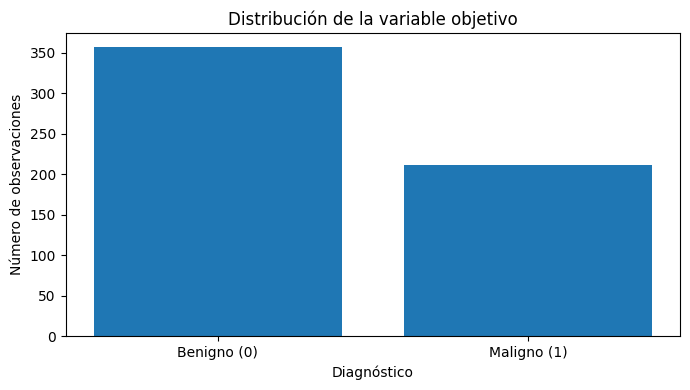

In [15]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Resumen de los datos
resumen = pd.DataFrame({
    "Indicador": [
        "Observaciones",
        "Variables predictoras",
        "Valores faltantes",
        "Entrenamiento",
        "Validación",
        "Prueba"
    ],
    "Valor": [569, 30, 0, 341, 114, 114]
})

display(resumen)

# Distribución de la variable objetivo
distribucion = pd.DataFrame({
    "Diagnóstico": ["Benigno (0)", "Maligno (1)"],
    "Frecuencia": [357, 212]
})

distribucion["Porcentaje"] = (
    distribucion["Frecuencia"] / 569 * 100
)

display(distribucion.round(2))

# Gráfico de barras
plt.figure(figsize=(7, 4))
plt.bar(distribucion["Diagnóstico"], distribucion["Frecuencia"])
plt.title("Distribución de la variable objetivo")
plt.xlabel("Diagnóstico")
plt.ylabel("Número de observaciones")
plt.tight_layout()
plt.show()

La clase benigna representa aproximadamente el 62,7 % de las observaciones, mientras que la clase maligna representa el 37,3 %. Esto indica que existe una diferencia moderada en la frecuencia de ambas clases. Por esta razón, se utiliza ROC AUC como métrica principal para evaluar la capacidad de discriminación de los modelos.

# Entrenamiento de los modelos

## Modelos supervisados seleccionados

Se entrenaron tres modelos de clasificación: Regresión Logística, K-Nearest Neighbors (KNN) y Árbol de Decisión. Estos modelos permiten comparar diferentes métodos de aprendizaje supervisado.

La Regresión Logística estima la probabilidad de pertenecer a una clase; KNN clasifica las observaciones considerando la cercanía entre ellas, y el Árbol de Decisión realiza clasificaciones mediante reglas sucesivas.

Los tres modelos se evaluaron utilizando ROC AUC para mantener un criterio de comparación uniforme.

In [16]:
# Separar entrenamiento (60%) y datos restantes (40%)
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y,
    test_size=0.40,
    random_state=42,
    stratify=y
)

# Separar validación (20%) y prueba (20%)
X_val, X_test, y_val, y_test = train_test_split(
    X_temp, y_temp,
    test_size=0.50,
    random_state=42,
    stratify=y_temp
)

# Mostrar las dimensiones de cada conjunto
print("Entrenamiento:", X_train.shape)
print("Validación:", X_val.shape)
print("Prueba:", X_test.shape)

Entrenamiento: (341, 30)
Validación: (114, 30)
Prueba: (114, 30)


# Comparación entre entrenamiento y validación

## Evaluación inicial de los modelos

En esta etapa se compara el desempeño de cada modelo en el conjunto de entrenamiento y en el conjunto de validación. El conjunto de entrenamiento permite observar qué tan bien se ajusta el modelo a los datos utilizados para aprender, mientras que el de validación permite examinar su desempeño en observaciones que no participaron en ese ajuste.

In [17]:
# Crear el pipeline de preprocesamiento
preprocesamiento = Pipeline([
    ("escalador", StandardScaler())
])

# Ajustar el escalador con entrenamiento y transformar los datos
X_train_scaled = preprocesamiento.fit_transform(X_train)

# Aplicar la misma transformación a validación y prueba
X_val_scaled = preprocesamiento.transform(X_val)
X_test_scaled = preprocesamiento.transform(X_test)

print("Entrenamiento estandarizado:", X_train_scaled.shape)
print("Validación estandarizada:", X_val_scaled.shape)
print("Prueba estandarizada:", X_test_scaled.shape)

Entrenamiento estandarizado: (341, 30)
Validación estandarizada: (114, 30)
Prueba estandarizada: (114, 30)


In [18]:
# Importar los modelos
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

# Definir los modelos con sus hiperparámetros por defecto
modelos = {
    "Regresión logística": LogisticRegression(),
    "KNN": KNeighborsClassifier(),
    "Árbol de decisión": DecisionTreeClassifier()
}

# Crear los pipelines
pipelines = {}

for nombre, modelo in modelos.items():
    pipelines[nombre] = Pipeline([
        ("escalador", StandardScaler()),
        ("modelo", modelo)
    ])

# Entrenar los modelos con los datos de entrenamiento
for nombre, pipeline in pipelines.items():
    pipeline.fit(X_train, y_train)
    print(nombre, "entrenado correctamente")

Regresión logística entrenado correctamente
KNN entrenado correctamente
Árbol de decisión entrenado correctamente


# Validación cruzada

## Evaluación con validación cruzada

Se evaluaron tres modelos de clasificación: regresión logística, K vecinos más cercanos (KNN) y árbol de decisión. Como métrica principal se utilizó el área bajo la curva ROC (ROC AUC), que permite medir la capacidad de los modelos para distinguir entre las clases de la variable objetivo.

Inicialmente, se calculó el ROC AUC sobre los conjuntos de entrenamiento y validación. Posteriormente, se aplicó validación cruzada estratificada de cinco folds sobre el conjunto de entrenamiento, registrando el resultado de cada partición, el promedio y la desviación estándar.

La comparación entre la validación y la validación cruzada permite analizar la consistencia de los resultados y la capacidad de generalización de los modelos. Para seleccionar el modelo más adecuado, se tendrá en cuenta un promedio de ROC AUC elevado, una desviación estándar reducida y un desempeño en validación coherente con los resultados de la validación cruzada.

El modelo seleccionado será aquel que presente el mejor equilibrio entre capacidad de discriminación y estabilidad, de acuerdo con los resultados obtenidos experimentalmente.

In [19]:

# Importar las librerías necesarias
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import StratifiedKFold, cross_val_score
from sklearn.metrics import roc_auc_score

# Definir validación cruzada de 5 folds
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Guardar los resultados
resultados = []
resultados_folds = {}

for nombre, pipeline in pipelines.items():

    # 1. Entrenar el modelo
    pipeline.fit(X_train, y_train)

    # 2. ROC AUC en entrenamiento
    prob_train = pipeline.predict_proba(X_train)[:, 1]
    auc_train = roc_auc_score(y_train, prob_train)

    # 3. ROC AUC en validación
    prob_val = pipeline.predict_proba(X_val)[:, 1]
    auc_val = roc_auc_score(y_val, prob_val)

    # 4. Validación cruzada sobre entrenamiento
    auc_folds = cross_val_score(
        pipeline,
        X_train,
        y_train,
        cv=cv,
        scoring="roc_auc"
    )

    # Guardar resultados de cada fold
    resultados_folds[nombre] = auc_folds

    # Registrar resultados comparativos
    resultados.append({
        "Modelo": nombre,
        "ROC AUC entrenamiento": auc_train,
        "ROC AUC validación": auc_val,
        "ROC AUC CV promedio": auc_folds.mean(),
        "Desviación estándar CV": auc_folds.std(),
        "Fold 1": auc_folds[0],
        "Fold 2": auc_folds[1],
        "Fold 3": auc_folds[2],
        "Fold 4": auc_folds[3],
        "Fold 5": auc_folds[4]
    })

# Crear tabla comparativa
tabla_resultados = pd.DataFrame(resultados)

print("Tabla comparativa de los modelos:")
display(tabla_resultados.round(4))


Tabla comparativa de los modelos:


,Modelo,ROC AUC entrenamiento,ROC AUC validación,ROC AUC CV promedio,Desviación estándar CV,Fold 1,Fold 2,Fold 3,Fold 4,Fold 5
0,Regresión logística,0.9971,1.0000,0.9939,0.0074,0.9991,0.9963,1.0000,0.9944,0.9795
1,KNN,0.9970,0.9959,0.9775,0.0208,1.0000,0.9771,0.9949,0.9409,0.9744
2,Árbol de decisión,1.0000,0.9021,0.9092,0.0238,0.9191,0.9231,0.9335,0.8651,0.9051


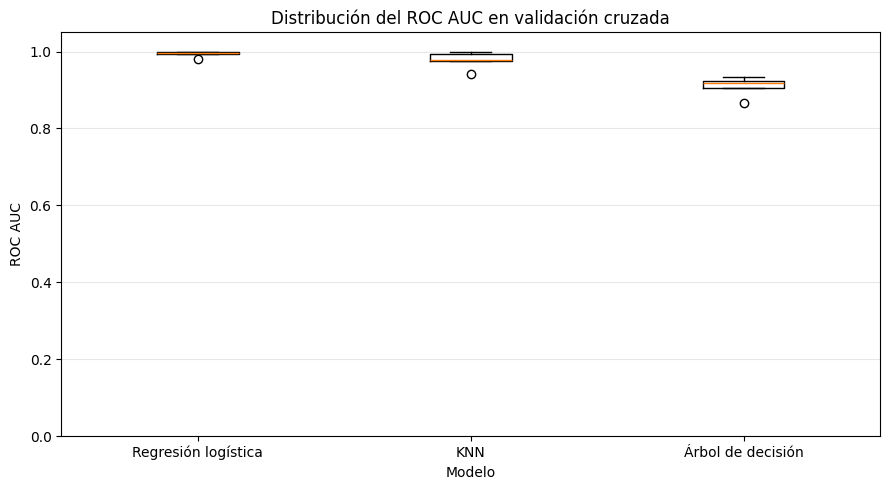

In [20]:

# Preparar los resultados de los cinco folds
datos_grafico = pd.DataFrame(resultados_folds)

# Crear gráfico de cajas
plt.figure(figsize=(9, 5))

plt.boxplot(
    [datos_grafico[col] for col in datos_grafico.columns],
    tick_labels=datos_grafico.columns
)

plt.title("Distribución del ROC AUC en validación cruzada")
plt.ylabel("ROC AUC")
plt.xlabel("Modelo")
plt.ylim(0, 1.05)
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()


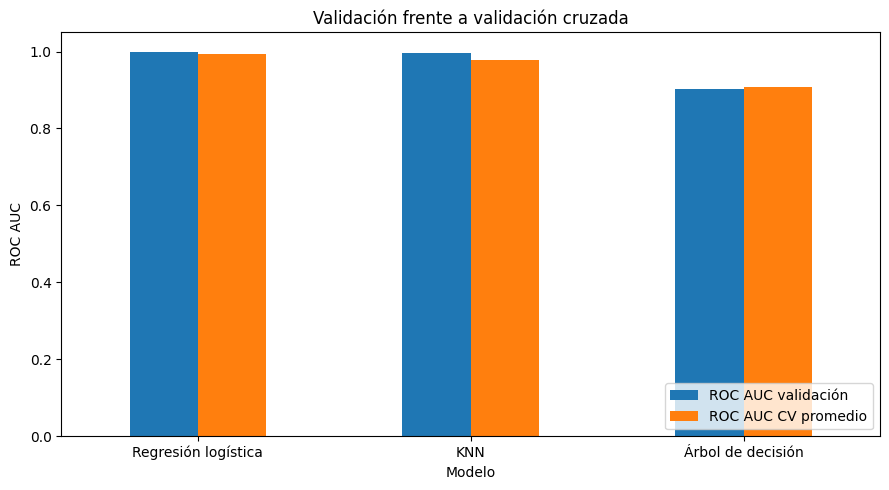

In [21]:

comparacion = tabla_resultados.set_index("Modelo")[
    ["ROC AUC validación", "ROC AUC CV promedio"]
]

comparacion.plot(
    kind="bar",
    figsize=(9, 5)
)

plt.title("Validación frente a validación cruzada")
plt.ylabel("ROC AUC")
plt.xlabel("Modelo")
plt.ylim(0, 1.05)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


Los resultados de la evaluación muestran diferencias en el desempeño de los tres modelos de clasificación. La regresión logística obtuvo el mejor resultado, con un ROC AUC promedio de 0.9939 y una desviación estándar de 0.0074, lo que indica una excelente capacidad para distinguir entre tumores benignos y malignos, además de una alta estabilidad entre los cinco folds. Sus resultados oscilaron entre 0.9795 y 1.0000, manteniéndose en niveles elevados en todas las particiones.
Por su parte, el modelo KNN alcanzó un ROC AUC promedio de 0.9775, con una desviación estándar de 0.0208. Aunque presenta un buen desempeño, su mayor variabilidad entre folds indica que sus resultados son menos estables que los de la regresión logística. Finalmente, el árbol de decisión obtuvo un ROC AUC promedio de 0.9092 y una desviación estándar de 0.0238, mostrando el menor desempeño de los tres modelos y una mayor variabilidad relativa.
Al comparar los resultados de entrenamiento, validación y validación cruzada, se observa que la regresión logística mantiene un rendimiento elevado en las distintas evaluaciones. En cambio, el árbol de decisión presenta un ROC AUC de 1.0000 en entrenamiento, que disminuye a 0.9021 en validación y a 0.9092 en promedio en validación cruzada. Esta diferencia sugiere un posible sobreajuste, ya que el modelo se ajusta perfectamente a los datos de entrenamiento, pero su capacidad de discriminación disminuye en datos no utilizados para ajustarlo.
En conclusión, la regresión logística es el modelo que presenta el mejor equilibrio entre desempeño y estabilidad, seguida de KNN y del árbol de decisión. Por tanto, se selecciona la regresión logística para realizar la evaluación final en el conjunto de prueba.

# Evaluación Final en el Conjunto de Prueba

A partir de los resultados obtenidos en la validación cruzada, se seleccionó el modelo con el mayor promedio de ROC AUC. Posteriormente, este modelo se entrenó nuevamente utilizando todo el conjunto de entrenamiento y se evaluó sobre el conjunto de prueba, que no había sido utilizado durante el proceso de selección.

El ROC AUC obtenido en prueba se comparó con el promedio de la validación cruzada para determinar si el comportamiento observado previamente se mantenía en datos no utilizados durante el entrenamiento. Una diferencia reducida entre ambas métricas sugiere que el modelo presenta un desempeño consistente. Por el contrario, una diferencia considerable puede indicar variabilidad en los resultados o dificultades para generalizar a nuevas observaciones.

La conclusión definitiva se establece a partir de los valores obtenidos en ambas evaluaciones.

##  Seleccionar y evaluar el mejor modelo

In [22]:

# Seleccionar el modelo con mayor ROC AUC promedio en CV
mejor_fila = tabla_resultados.loc[
    tabla_resultados["ROC AUC CV promedio"].idxmax()
]

mejor_nombre = mejor_fila["Modelo"]
mejor_modelo = pipelines[mejor_nombre]

# Reentrenar con todo el conjunto de entrenamiento
mejor_modelo.fit(X_train, y_train)

# Evaluar en el conjunto de prueba
prob_test = mejor_modelo.predict_proba(X_test)[:, 1]
auc_test = roc_auc_score(y_test, prob_test)

# Recuperar el promedio de validación cruzada
auc_cv = mejor_fila["ROC AUC CV promedio"]

# Mostrar los resultados
print("Mejor modelo:", mejor_nombre)
print("ROC AUC promedio en CV:", round(auc_cv, 4))
print("Desviación estándar en CV:",
      round(mejor_fila["Desviación estándar CV"], 4))
print("ROC AUC en prueba:", round(auc_test, 4))
print("Diferencia absoluta:", round(abs(auc_test - auc_cv), 4))


Mejor modelo: Regresión logística
ROC AUC promedio en CV: 0.9939
Desviación estándar en CV: 0.0074
ROC AUC en prueba: 0.994
Diferencia absoluta: 0.0002


## Comparar la validación cruzada con la prueba

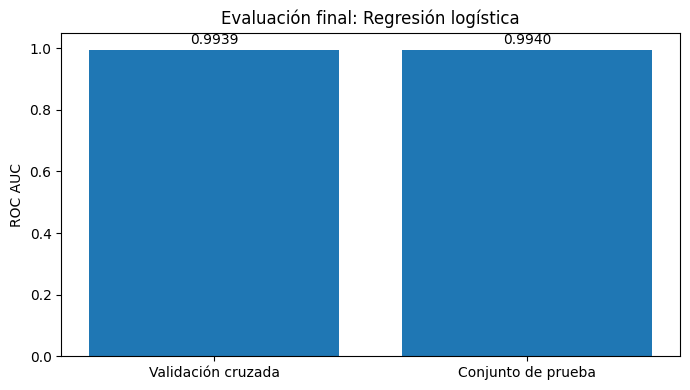

In [23]:

import matplotlib.pyplot as plt

metricas_finales = [
    "Validación cruzada",
    "Conjunto de prueba"
]

valores_finales = [auc_cv, auc_test]

plt.figure(figsize=(7, 4))

barras = plt.bar(metricas_finales, valores_finales)

plt.title(f"Evaluación final: {mejor_nombre}")
plt.ylabel("ROC AUC")
plt.ylim(0, 1.05)

for barra, valor in zip(barras, valores_finales):
    plt.text(
        barra.get_x() + barra.get_width() / 2,
        barra.get_height() + 0.02,
        f"{valor:.4f}",
        ha="center"
    )

plt.tight_layout()
plt.show()


La regresión logística fue seleccionada como el mejor modelo a partir de los resultados de la validación cruzada. Posteriormente, se entrenó nuevamente con el conjunto de entrenamiento y se evaluó sobre el conjunto de prueba, obteniendo un ROC AUC de 0.9940.
Este resultado es prácticamente idéntico al ROC AUC promedio de la validación cruzada, que fue de 0.9939, con una diferencia absoluta de apenas 0.0002 según los valores reportados. Esta similitud indica que el desempeño del modelo se mantiene en observaciones que no fueron utilizadas durante su entrenamiento, lo que constituye evidencia favorable de su capacidad de generalización.
Además, la desviación estándar de 0.0074 obtenida en la validación cruzada confirma que el rendimiento de la regresión logística fue relativamente estable entre las distintas particiones del conjunto de entrenamiento. En conjunto, estos resultados respaldan la elección de este modelo frente a las otras alternativas evaluadas.
En conclusión, la regresión logística presenta un desempeño excelente y consistente, tanto en validación cruzada como en el conjunto de prueba, por lo que resulta ser el modelo más adecuado entre los tres comparados para este problema de clasificación.